# 0c — Préparation des données · Segment : Comptes joints

**Objectif** : dérouler le chapitre 2 du cours sur le segment *comptes joints* (`nb_tiers > 1`),
avant l'analyse exploratoire (ch. 3) et la discrétisation (ch. 4).

| § | Thème | Traitement appliqué ici |
|---|-------|-------------------------|
| 2.1 | Sources de données | inventaire des variables disponibles |
| 2.2 | Valeurs manquantes | analyse, puis **missing conservé comme modalité** |
| 2.3 | Outliers | valeurs aberrantes → manquant ; valeurs extrêmes → winsorisation |
| 2.4 | Feature engineering | ratios |
| 2.5 | Variables interdites | repérage et exclusion |
| — | Présélection | exclusion des variables quasi vides, quasi constantes, non discriminantes ou redondantes |

> Ce notebook est un **rapport lisible** : les calculs sont délégués à `utils/stats_descriptives.py`
> et `utils/exploration.py`. Seuls les paramètres et les décisions figurent ici.

## 0. Imports et configuration

In [9]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path(".").resolve()))

import polars as pl
import matplotlib.pyplot as plt

from utils.binning import iv_ranking
from utils.exploration import (
    nan_to_null, outlier_report, exporter_excel,
    constant_report, paires_redondantes, cramers_v_matrix, paires_fortes, preselection_variables,
)
from utils.stats_descriptives import (
    profil_segment, grille_quanti, plot_taux_missing,
    table_missing, plot_missing_tdr, missing_en_modalite,
    valeurs_aberrantes, winsoriser, ajouter_ratios, reperer_variables, bilan_variables,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)

polars.config.Config

In [10]:
from pathlib import Path

BASE     = Path("data/segments/joint/base_joint.parquet")
SORTIE   = Path("data/segments/joint/base_joint_prep.parquet")

TARGET   = "ddefaut_ndb"   # variable cible (0/1)
ID_COL   = "gdt"           # identifiant
DATE_COL = "datdelhis"     # date d'observation

# Colonnes techniques, hors du champ des variables explicatives
EXCLUDE  = [ID_COL, TARGET, DATE_COL, "segment", "SelectionProb", "SamplingWeight",
            "type_PM_PP", "code_marche_v2"]

# Une variable numérique de plus de MAX_MODALITES valeurs distinctes est traitée comme continue
MAX_MODALITES = 15

## 1. Chargement

La base du segment est produite par le notebook `0 - Segmentation_exploration.ipynb`.
Les `NaN` des colonnes flottantes sont convertis en `null` : sans cela ils ne seraient pas
comptés comme manquants.

In [11]:
if not BASE.exists():
    raise FileNotFoundError(f"{BASE.resolve()} introuvable : lancer le notebook depuis la racine du projet.")

df = nan_to_null(pl.read_parquet(BASE))

manquantes = [c for c in (TARGET, ID_COL, DATE_COL) if c and c not in df.columns]
assert not manquantes, f"Colonnes absentes de la base : {manquantes}"

EXCLUDE = [c for c in EXCLUDE if c in df.columns]

print(f"Base chargée : {df.height} lignes, {df.width} colonnes")

Base chargée : 58947 lignes, 193 colonnes


## 2.1 Sources de données

Inventaire de ce qui est disponible : volume, taux de défaut, période couverte, et répartition
des variables par nature.

> **À compléter** : origine de chaque famille de variables (données de production internes,
> données externes payantes, open banking) et date de disponibilité par rapport à la date
> d'observation. Une variable connue seulement *après* `datdelhis` doit être écartée (fuite d'information).

In [12]:
profil_segment(df, target=TARGET, id_col=ID_COL, date_col=DATE_COL)

n_total,n_defaut,n_sain,taux_defaut,date_min,date_max
i64,i64,i64,f64,str,str
58947,284,58663,0.004818,"""2021-01-01""","""2021-04-01"""


In [13]:
VARS        = [c for c, t in df.schema.items() if c not in EXCLUDE and not t.is_temporal()]
VARS_QUANTI = [c for c in VARS if df.schema[c].is_numeric()]
VARS_QUALI  = [c for c in VARS if c not in VARS_QUANTI]
VARS_CONTINUES = [c for c in VARS_QUANTI if df[c].n_unique() > MAX_MODALITES]

print(f"{len(VARS)} variables explicatives candidates")
print(f"  - {len(VARS_QUANTI)} quantitatives, dont {len(VARS_CONTINUES)} continues (> {MAX_MODALITES} valeurs distinctes)")
print(f"  - {len(VARS_QUALI)} qualitatives")

pl.DataFrame({"dtype": [str(df.schema[c]) for c in VARS]}).group_by("dtype").len().sort("len", descending=True)

182 variables explicatives candidates
  - 155 quantitatives, dont 94 continues (> 15 valeurs distinctes)
  - 27 qualitatives


dtype,len
str,u32
"""Float64""",155
"""String""",19
"""Boolean""",6
"""Enum(categories=['18-25', '25-…",1
"""Enum(categories=['<1an', '1-2a…",1


## 2.2 Valeurs manquantes

**Principe du cours** : le manquant n'est ni imputé ni supprimé, il est **conservé comme une modalité
à part entière**. L'absence d'information est souvent elle-même porteuse de risque.

L'analyse ci-dessous sert à le vérifier variable par variable : on compare le taux de défaut des
dossiers manquants à celui des dossiers renseignés.

- `ecart_tdr` : taux de défaut des manquants − taux de défaut des renseignés ;
- `pvalue` : test du Chi² d'indépendance entre l'indicatrice « manquant » et la cible.

In [14]:
tab_missing = table_missing(df, target=TARGET, columns=VARS)

n_avec = tab_missing.filter(pl.col("n_missing") > 0).height
print(f"{n_avec} variables sur {len(VARS)} comportent au moins un manquant")

tab_missing.filter(pl.col("n_missing") > 0)

38 variables sur 182 comportent au moins un manquant


variable,dtype,n_missing,taux_missing,tdr_missing,tdr_renseigne,ecart_tdr,pvalue
str,str,i64,f64,f64,f64,f64,f64
"""AGE_PM_EN_MOIS""","""Float64""",58947,1.0,0.004818,null,null,null
"""CODACVPRO_modif""","""Float64""",58947,1.0,0.004818,null,null,null
"""CODNAF2""","""String""",58947,1.0,0.004818,null,null,null
"""CODETAJUR""","""String""",58947,1.0,0.004818,null,null,null
"""CRTOC_TOK_0010""","""String""",58947,1.0,0.004818,null,null,null
"""RATIO_LITIGES_vs_CA""","""Float64""",58947,1.0,0.004818,null,null,null
"""flux_pro""","""String""",58947,1.0,0.004818,null,null,null
"""MVTAFF_STABILITE_2T_vs_12M""","""Float64""",56850,0.964426,0.004661,0.009061,-0.004399,0.007007
"""CODITDBDF_PRO""","""String""",56770,0.963069,0.004668,0.008728,-0.00406,0.01151


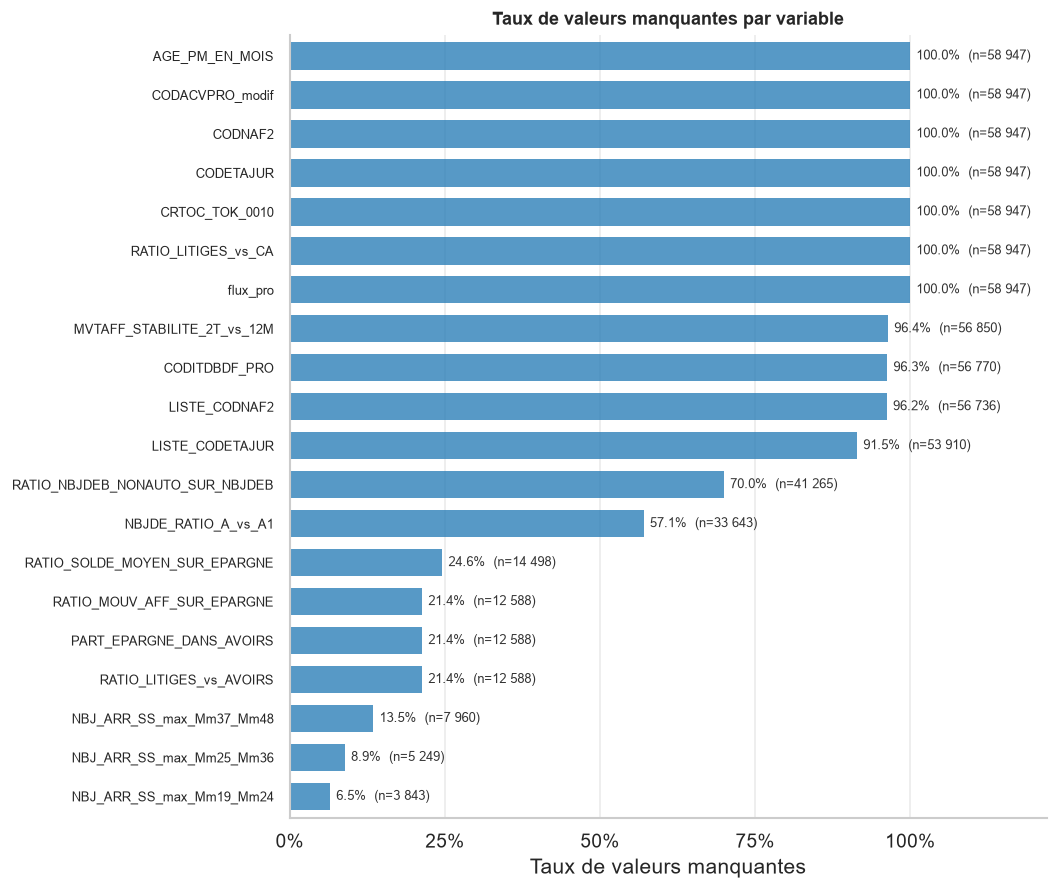

In [15]:
SEUIL_AFFICHAGE = 0.05   # seules les variables au-delà de ce taux de manquants sont tracées

fig = plot_taux_missing(df, columns=VARS, seuil_affichage=SEUIL_AFFICHAGE, top_n=30)
plt.show()

### Le manquant est-il informatif ?

Variables où le taux de défaut des manquants s'écarte le plus de celui des renseignés.

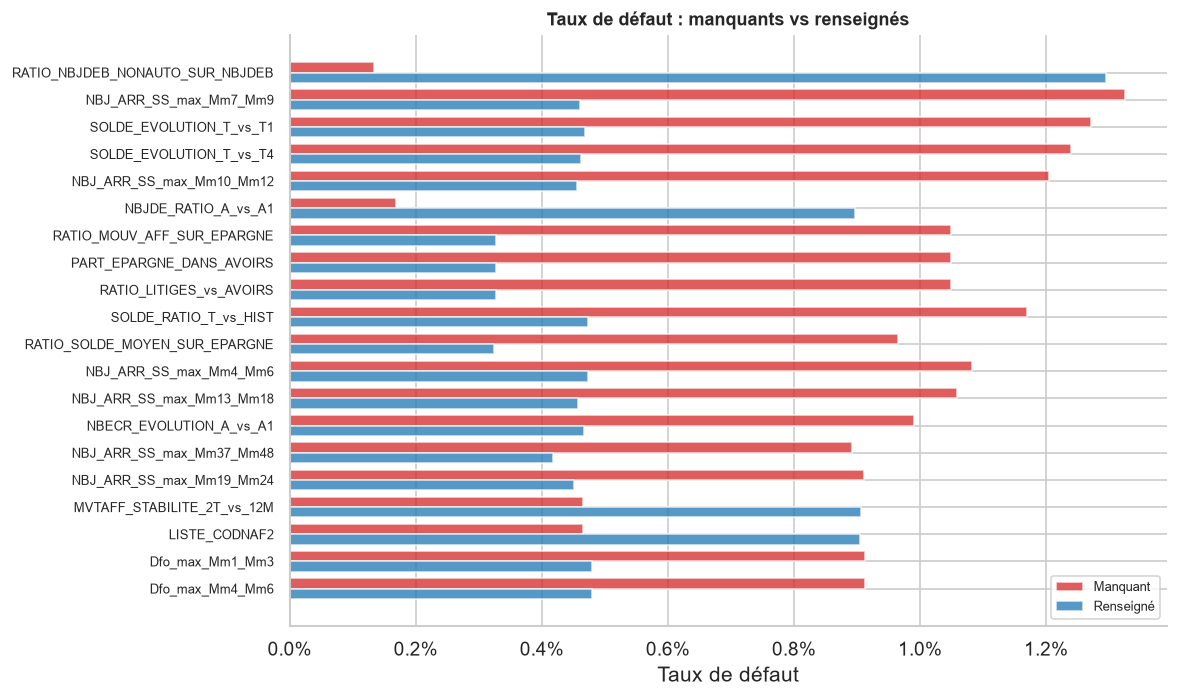

In [16]:
fig = plot_missing_tdr(tab_missing, top_n=20, n_min=30)
plt.show()

In [17]:
ALPHA = 0.05

informatifs = tab_missing.filter(pl.col("pvalue") < ALPHA).sort(pl.col("ecart_tdr").abs(), descending=True)
print(f"{informatifs.height} variables dont le manquant est lié au défaut (p < {ALPHA})")
informatifs

20 variables dont le manquant est lié au défaut (p < 0.05)


variable,dtype,n_missing,taux_missing,tdr_missing,tdr_renseigne,ecart_tdr,pvalue
str,str,i64,f64,f64,f64,f64,f64
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…","""Float64""",41265,0.700036,0.001333,0.012951,-0.011618,3.0662e-77
"""NBJ_ARR_SS_max_Mm7_Mm9""","""Float64""",1434,0.024327,0.01325,0.004608,0.008642,0.000008
"""SOLDE_EVOLUTION_T_vs_T1""","""Float64""",944,0.016014,0.012712,0.004689,0.008022,0.000987
"""SOLDE_EVOLUTION_T_vs_T4""","""Float64""",1532,0.025989,0.012402,0.004616,0.007787,0.000032
"""NBJ_ARR_SS_max_Mm10_Mm12""","""Float64""",1992,0.033793,0.012048,0.004565,0.007483,0.000005
"""NBJDE_RATIO_A_vs_A1""","""Float64""",33643,0.570733,0.001694,0.008971,-0.007277,3.1366e-36
"""RATIO_MOUV_AFF_SUR_EPARGNE""","""Float64""",12588,0.213548,0.010486,0.003279,0.007207,8.3230e-25
"""PART_EPARGNE_DANS_AVOIRS""","""Float64""",12588,0.213548,0.010486,0.003279,0.007207,8.3230e-25
"""RATIO_LITIGES_vs_AVOIRS""","""Float64""",12588,0.213548,0.010486,0.003279,0.007207,8.3230e-25


### Variables presque entièrement manquantes

Elles sont signalées ici et **retirées à l'étape de présélection**, en fin de notebook.

In [18]:
SEUIL_QUASI_VIDE = 0.95

tab_missing.filter(pl.col("taux_missing") >= SEUIL_QUASI_VIDE)

variable,dtype,n_missing,taux_missing,tdr_missing,tdr_renseigne,ecart_tdr,pvalue
str,str,i64,f64,f64,f64,f64,f64
"""AGE_PM_EN_MOIS""","""Float64""",58947,1.0,0.004818,null,null,null
"""CODACVPRO_modif""","""Float64""",58947,1.0,0.004818,null,null,null
"""CODNAF2""","""String""",58947,1.0,0.004818,null,null,null
"""CODETAJUR""","""String""",58947,1.0,0.004818,null,null,null
"""CRTOC_TOK_0010""","""String""",58947,1.0,0.004818,null,null,null
"""RATIO_LITIGES_vs_CA""","""Float64""",58947,1.0,0.004818,null,null,null
"""flux_pro""","""String""",58947,1.0,0.004818,null,null,null
"""MVTAFF_STABILITE_2T_vs_12M""","""Float64""",56850,0.964426,0.004661,0.009061,-0.004399,0.007007
"""CODITDBDF_PRO""","""String""",56770,0.963069,0.004668,0.008728,-0.00406,0.01151


### Décision

- **Aucune ligne n'est supprimée** pour cause de valeurs manquantes. Seules les variables presque
  entièrement manquantes sont retirées, à l'étape de présélection.
- Variables **qualitatives** : le manquant devient la modalité explicite `"missing"`.
- Variables **quantitatives** : le manquant reste `null` ; il formera une classe à part lors de la
  discrétisation (ch. 4), avec son propre WOE.

> **À compléter** : commentaire sur les variables les plus manquantes et sur celles dont le manquant
> est informatif (interprétation métier de l'absence).

In [19]:
df_prep = missing_en_modalite(df, columns=VARS_QUALI)

reste = sum(df_prep[c].null_count() for c in VARS_QUALI)
print(f"Manquants restants dans les variables qualitatives : {reste}")

Manquants restants dans les variables qualitatives : 0


## 2.3 Outliers

On distingue deux cas, traités différemment :

1. **Valeurs aberrantes** : impossibles d'un point de vue métier (âge négatif, taux supérieur à 100 %…).
   Ce sont des erreurs : elles sont remplacées par un manquant.
2. **Valeurs extrêmes** : plausibles mais très éloignées du reste de la distribution.
   Elles sont détectées (règle IQR) puis écrêtées par winsorisation.

### Valeurs aberrantes

> **À compléter** : plages admissibles des variables dont le domaine est connu.

In [20]:
# {variable: (min admissible, max admissible)} ; None = pas de borne
PLAGES = {
    # "AGE_PM_EN_MOIS": (0, None),
}
PLAGES = {c: p for c, p in PLAGES.items() if c in df_prep.columns}

df_prep, rapport_aberrantes = valeurs_aberrantes(df_prep, PLAGES)
rapport_aberrantes

variable,min_admissible,max_admissible,n_aberrantes,taux_aberrantes
str,f64,f64,i64,f64


### Valeurs extrêmes — détection

Règle IQR : une valeur est extrême si elle sort de `[Q1 − k·IQR ; Q3 + k·IQR]`.
On prend `k = 3` (valeurs « très » extrêmes) plutôt que 1,5 : les variables de montants sont
naturellement asymétriques et la règle à 1,5 en signalerait une part trop importante.

In [21]:
K_IQR = 3

rapport_outliers = (
    outlier_report(df_prep, columns=VARS_CONTINUES, method="iqr", k=K_IQR)
    .sort("taux_outliers", descending=True, nulls_last=True)
)
rapport_outliers.filter(pl.col("n_outliers") > 0)

variable,n_outliers,taux_outliers,borne_basse,borne_haute
str,i64,f64,f64,f64
"""engagement_immo__crelog""",12878,0.218467,-41397.36,55196.48
"""CRTAR_IND_0036""",12202,0.207,0.0,0.0
"""solde_debiteur""",11981,0.20325,-3040.0,2280.0
"""CRTAV_IND_0165""",11290,0.191528,-476419.5,635226.0
"""CRTAD_IND_0015""",9661,0.163893,-6.0,8.0
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",7154,0.160949,-6.453906,8.888647
"""engagement_credit_perso""",8436,0.143112,0.0,0.0
"""SOLDE_PENTE_3T""",8220,0.139447,-182084.5,192417.25
"""SOLDE_PENTE_4T""",8071,0.13692,-147350.35,170916.9


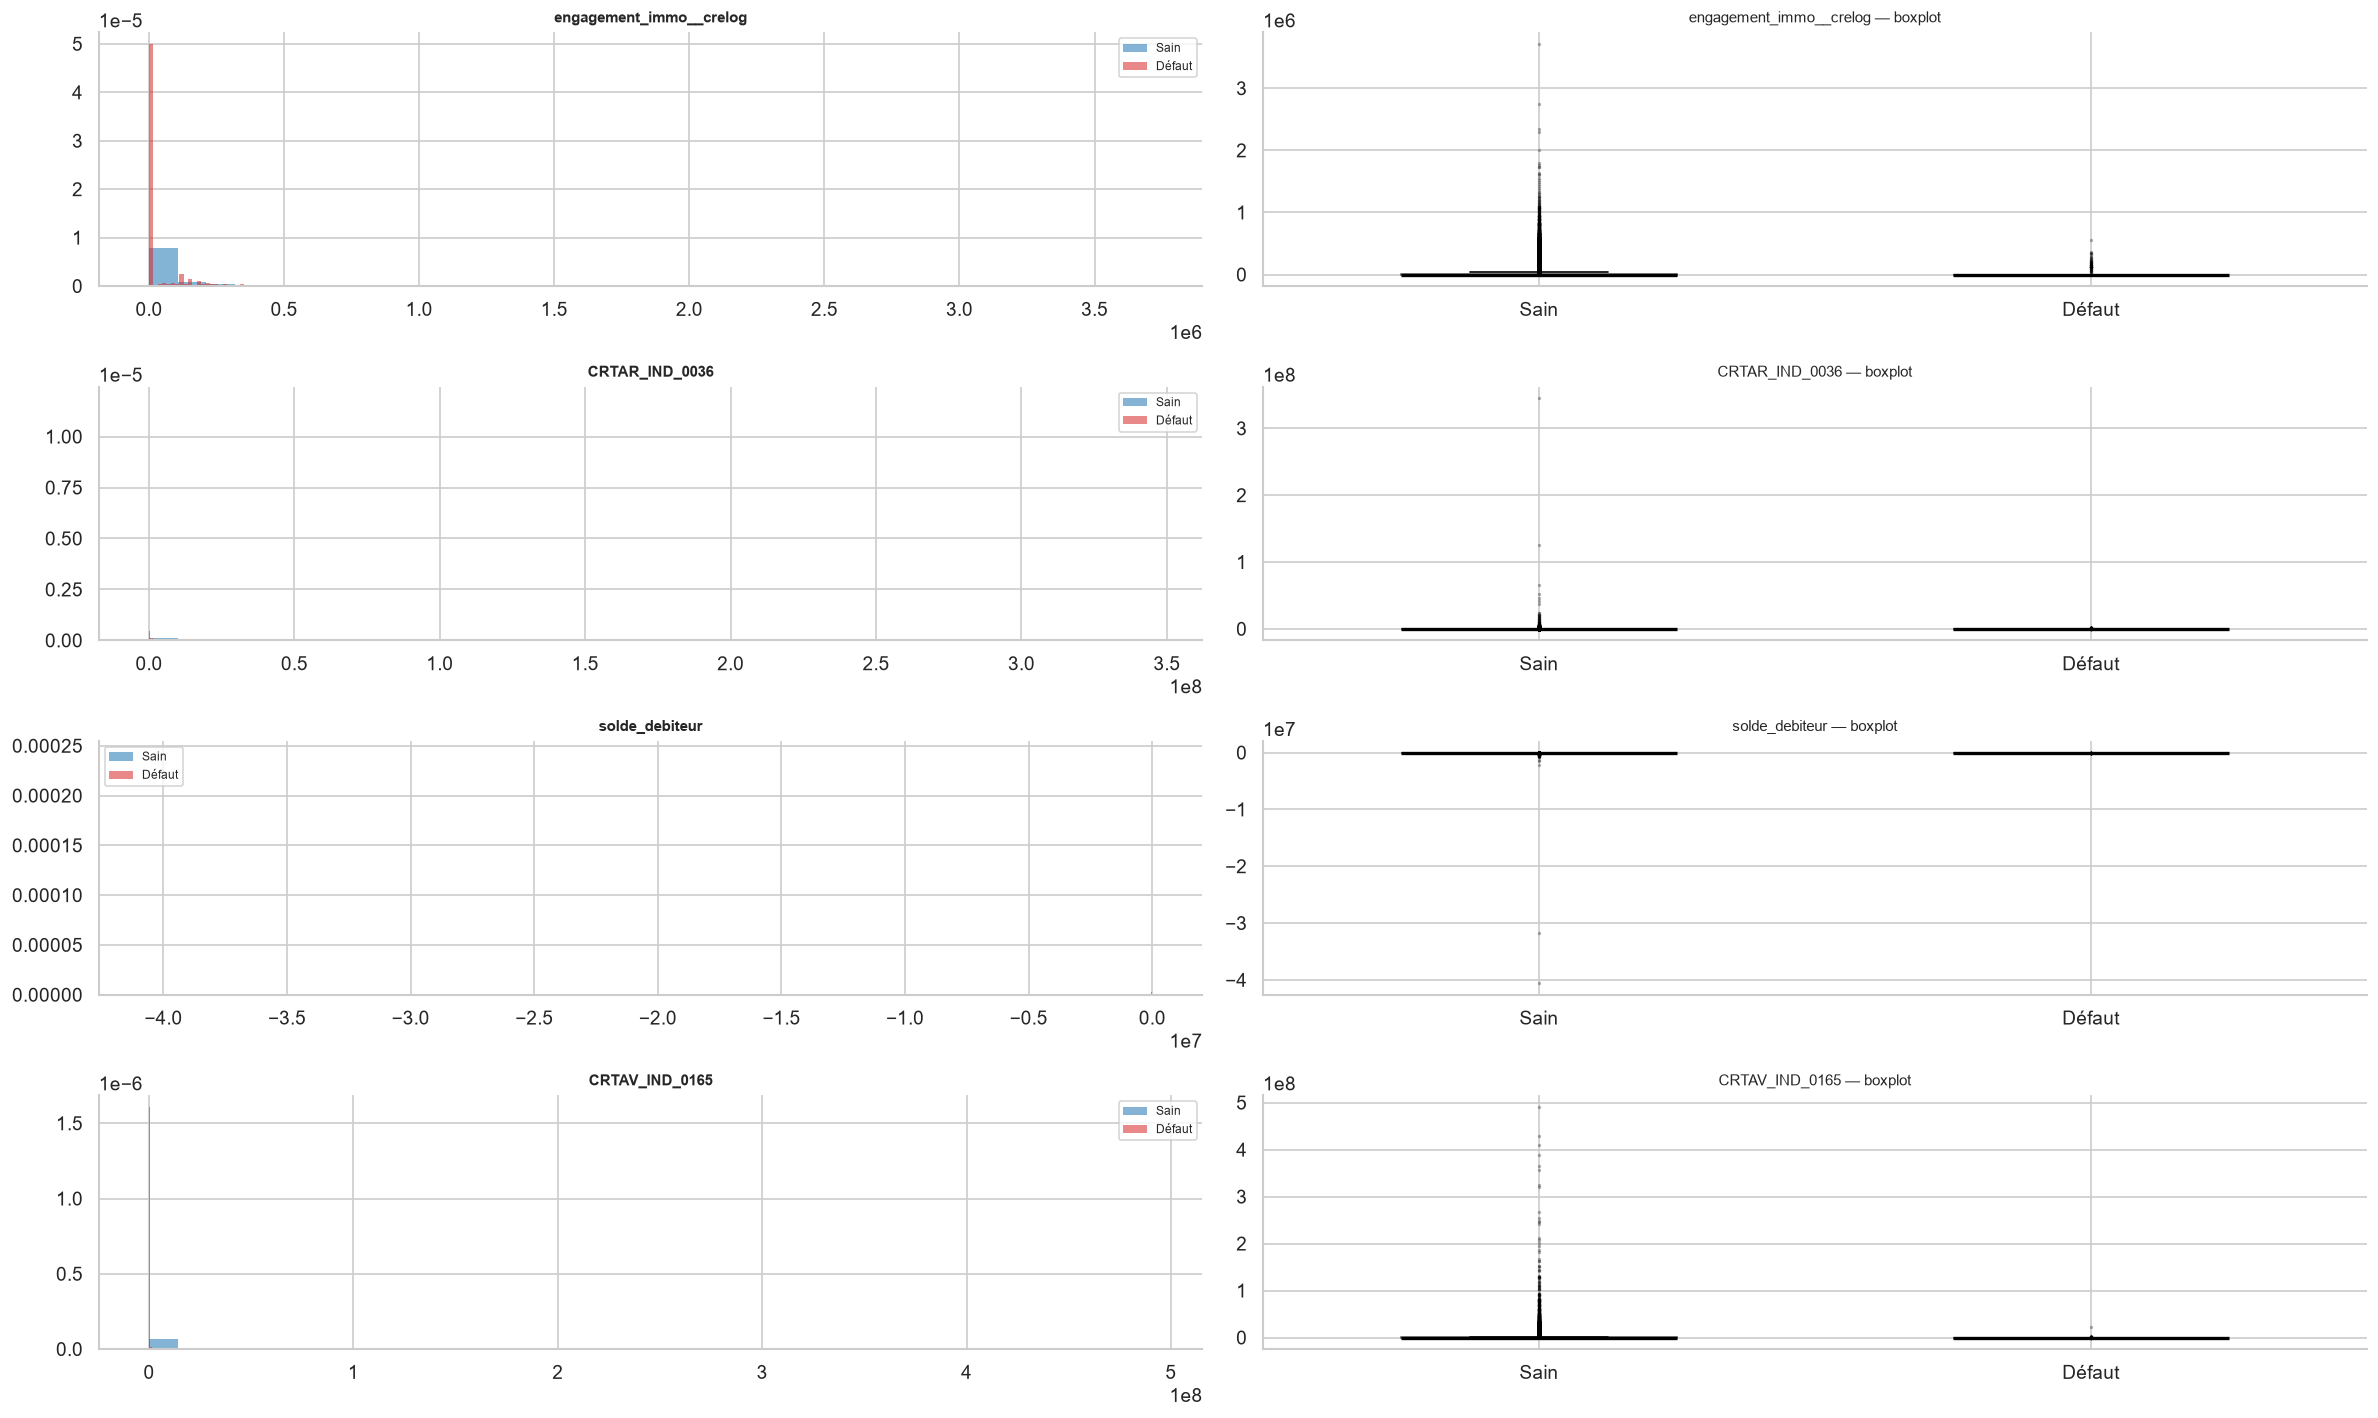

In [22]:
# Distributions des variables les plus touchées
VARS_OUTLIERS_PLOT = rapport_outliers.filter(pl.col("n_outliers") > 0)["variable"].head(4).to_list()

if VARS_OUTLIERS_PLOT:
    fig = grille_quanti(df_prep, variables=VARS_OUTLIERS_PLOT, target=TARGET)
    plt.show()

### Valeurs extrêmes — traitement

Winsorisation aux quantiles 1 % et 99 % : les valeurs au-delà sont ramenées à la borne.
Aucune observation n'est supprimée, ce qui préserve le volume de défauts.

Deux remarques :

- La discrétisation (ch. 4) absorbe de toute façon les extrêmes dans les classes de bord : la
  winsorisation compte surtout pour les statistiques descriptives, les corrélations de Pearson et
  les ratios construits ensuite.
- Les bornes sont estimées ici sur tout le segment. Une fois le découpage apprentissage / test
  réalisé, elles devront être estimées sur l'apprentissage seul puis réappliquées
  (`winsoriser(..., bornes=bornes)`).

Une variable dont les deux bornes coïncident (comptage presque toujours nul) n'est pas modifiée.

In [23]:
P_BAS, P_HAUT = 0.01, 0.99

df_prep, bornes = winsoriser(df_prep, columns=VARS_CONTINUES, p_bas=P_BAS, p_haut=P_HAUT)

print(f"{bornes['winsorisee'].sum()} variables winsorisées sur {len(VARS_CONTINUES)}")
bornes.sort("taux_ecrete", descending=True, nulls_last=True)

80 variables winsorisées sur 94


variable,borne_basse,borne_haute,n_bas,n_haut,taux_ecrete,winsorisee
str,f64,f64,i64,i64,f64,bool
"""SOLDE_RATIO_T_vs_HIST""",-3.281846,13.731663,582,582,0.020008,true
"""SOLDE_EVOLUTION_T_vs_T1""",-1.847987,13.324964,580,580,0.019999,true
"""SOLDE_EVOLUTION_T_vs_T4""",-2.318603,44.006104,574,574,0.019995,true
"""CRTAD_IND_0038""",-102000.0,1.5269e7,589,589,0.019984,true
"""CRTAD_AG_SOLDE_T""",-53999.5,8.876833e6,589,589,0.019984,true
"""CRTAD_AG_SOLDE_T1""",-53667.0,8.719999e6,589,589,0.019984,true
"""MINSOLDE_PAR""",-107500.0,5.888166e6,589,589,0.019984,true
"""SOLDE_PENTE_5T""",-674250.0,1107616.7,589,589,0.019984,true
"""SOLDE_PENTE_4T""",-857149.95,1260000.1,589,589,0.019984,true


## 2.5 Variables interdites, RGPD et AI Act

Certaines variables ne peuvent pas entrer dans un score d'octroi, quel que soit leur pouvoir
discriminant : données sensibles au sens du RGPD (art. 9 : origine, opinions, religion, santé…) et
critères de discrimination prohibés (sexe, nationalité…). Le scoring de crédit étant un système
**à haut risque** au sens de l'AI Act, chaque variable retenue doit en outre pouvoir être justifiée.

Le repérage ci-dessous se fait **sur le nom des colonnes** : c'est un premier filtre, qui ne remplace
pas la relecture du dictionnaire de données.

In [25]:
MOTIFS_INTERDITS = {
    "age":           ["AGE_PP_EN_MOIS", "AGE_PM_EN_MOIS"]
}

reperage = reperer_variables(df_prep.select(VARS), MOTIFS_INTERDITS)
reperage

variable,famille,motif,dtype
str,str,str,str
"""AGE_PP_EN_MOIS""","""age""","""AGE_PP_EN_MOIS""","""Float64"""
"""AGE_PM_EN_MOIS""","""age""","""AGE_PM_EN_MOIS""","""Float64"""


### Décision

Par défaut, toutes les variables repérées sont exclues. Ajuster la liste après relecture :
retirer les faux positifs, ajouter les variables interdites que le nom ne trahit pas.

> **À compléter** : justification de chaque exclusion.

In [26]:
VARS_INTERDITES = reperage["variable"].unique(maintain_order=True).to_list()
# VARS_INTERDITES += ["..."]

df_prep = df_prep.drop(VARS_INTERDITES)
print(f"{len(VARS_INTERDITES)} variables exclues : {VARS_INTERDITES}")

2 variables exclues : ['AGE_PP_EN_MOIS', 'AGE_PM_EN_MOIS']


## Présélection des variables

Quatre motifs d'exclusion, appliqués dans cet ordre (une variable ne reçoit que le premier motif qui la concerne) :

| Motif | Règle | Paramètre |
|-------|-------|-----------|
| Quasi constante | une même valeur (manquant compris) couvre au moins 99 % des dossiers | `SEUIL_CONSTANTE` |
| Trop de manquants | taux de manquants ≥ 95 % | `MISSING_MAX` |
| Non discriminante | IV < 0,02 (seuil de Siddiqi), sur un découpage fin en déciles | `IV_MIN` |
| Redondante | \|Spearman\| ≥ 0,8 (quantitatives) ou V de Cramer ≥ 0,8 (qualitatives) avec une variable de meilleur IV | `SEUIL_CORR`, `SEUIL_CRAMER` |

Pour la redondance, les variables sont parcourues par IV décroissant : dans un groupe de variables
liées, c'est la plus discriminante qui est gardée, les autres sont exclues et la colonne
`redondante_avec` indique laquelle les représente.

Une variable d'IV > 0,5 est gardée mais signalée : un pouvoir discriminant aussi élevé fait
soupçonner une fuite d'information.

> Ces outils (IV, corrélations, V de Cramer) relèvent des chapitres 3 et 4 ; ils sont utilisés ici
> par anticipation, pour alléger la base avant l'analyse exploratoire.

In [27]:
IV_MIN          = 0.02    # IV en dessous duquel la variable est jugée non discriminante
MISSING_MAX     = 0.95    # taux de manquants à partir duquel la variable est exclue
SEUIL_CONSTANTE = 0.99    # part de la valeur la plus fréquente à partir de laquelle la variable est quasi constante
SEUIL_CORR      = 0.9     # |Spearman| à partir duquel deux variables quantitatives sont redondantes
SEUIL_CRAMER    = 0.9     # V de Cramer à partir duquel deux variables qualitatives sont redondantes
MAX_MODALITES_V = 50      # au-delà, une variable qualitative est laissée hors des V de Cramer
# Toute variable quasi constante est exclue. Mettre 0.1 pour garder celles dont l'IV atteint 0,1
# (valeur rare mais très discriminante).
IV_RARE         = float("inf")

VARS_PRE      = [c for c in VARS if c in df_prep.columns]
QUANTI_PRE    = [c for c in VARS_PRE if df_prep.schema[c].is_numeric()]
n_valeurs     = {c: df_prep[c].n_unique() for c in VARS_PRE}
DISCRETES_PRE = [c for c in VARS_PRE
                 if 1 < n_valeurs[c] <= (MAX_MODALITES if c in QUANTI_PRE else MAX_MODALITES_V)]

iv = iv_ranking(df_prep, VARS_PRE, TARGET)

# Taux de manquants : mesuré avant préparation pour les qualitatives (leur manquant est devenu une modalité)
taux_missing = dict(zip(tab_missing["variable"], tab_missing["taux_missing"]))
taux_missing |= {c: df_prep[c].null_count() / df_prep.height for c in QUANTI_PRE}

fiche = (
    constant_report(df_prep, VARS_PRE, seuil=SEUIL_CONSTANTE).select("variable", "part_top", "quasi_constante")
    .join(iv.select("variable", "iv", "pouvoir"), on="variable")
    .with_columns(taux_missing=pl.col("variable").replace_strict(taux_missing, return_dtype=pl.Float64))
)

paires_quanti = paires_redondantes(df_prep, QUANTI_PRE, seuil=SEUIL_CORR)
paires_quali  = paires_fortes(cramers_v_matrix(df_prep, DISCRETES_PRE), SEUIL_CRAMER, "cramers_v")
paires = pl.concat([paires_quanti.select("var1", "var2"), paires_quali.select("var1", "var2")])
print(f"{paires_quanti.height} paires redondantes (Spearman), {paires_quali.height} paires redondantes (V de Cramer)")

preselection = preselection_variables(
    fiche, paires, iv_min=IV_MIN, missing_max=MISSING_MAX, iv_rare=IV_RARE,
).sort("iv", descending=True)

preselection.group_by("statut").agg(n_variables=pl.len()).sort("n_variables", descending=True)

95 paires redondantes (Spearman), 30 paires redondantes (V de Cramer)


statut,n_variables
str,u32
"""écartée : quasi constante""",68
"""candidate""",46
"""écartée : redondante""",23
"""écartée : non discriminante (I…",20
"""candidate : IV > 0,5, vérifier…",20
"""écartée : trop de manquants""",3


### Variables exclues à la présélection

In [28]:
ecartees = preselection.filter(pl.col("statut").str.starts_with("écartée"))

with pl.Config(tbl_rows=-1, fmt_str_lengths=80):
    display(ecartees.select("variable", "statut", "iv", "taux_missing", "part_top", "redondante_avec")
            .sort("statut", "variable"))

variable,statut,iv,taux_missing,part_top,redondante_avec
str,str,f64,f64,f64,str
"""CRTOC_AG_LIGCRE_2T_IND_0009""","""écartée : non discriminante (IV < 0,02)""",0.019043,0.0,0.964612,null
"""CRTOC_AG_LIGDEB_IND_0015""","""écartée : non discriminante (IV < 0,02)""",0.0,0.0,0.986106,null
"""CRTOC_AG_MVTAFF_2T_IND_0010""","""écartée : non discriminante (IV < 0,02)""",0.016517,0.0,0.965545,null
"""CRTOC_AG_NBJCRE_2T_IND_0009""","""écartée : non discriminante (IV < 0,02)""",0.018735,0.0,0.964409,null
"""CRTOC_IND_0010""","""écartée : non discriminante (IV < 0,02)""",0.013048,0.0,0.968395,null
"""CRTOC_IND_0164""","""écartée : non discriminante (IV < 0,02)""",0.014422,0.0,0.969396,null
"""CRTOC_MOY_MVTAFF_IND_0010""","""écartée : non discriminante (IV < 0,02)""",0.013048,0.0,0.968395,null
"""CRTOC_SLD_MOY""","""écartée : non discriminante (IV < 0,02)""",0.009912,0.0,0.965817,null
"""NB_CCT_PRO""","""écartée : non discriminante (IV < 0,02)""",0.004124,0.0,0.988549,null


### Décision

> **À compléter** : commentaire des exclusions, en particulier pour la redondance (la variable gardée
> est-elle la plus lisible d'un point de vue métier ?) et pour les alertes IV > 0,5.

In [29]:
MOTIFS_PRESELECTION = {
    r["variable"]: (f"redondante avec {r['redondante_avec']}" if r["statut"] == "écartée : redondante"
                    else r["statut"].removeprefix("écartée : "))
    for r in ecartees.iter_rows(named=True)
}

df_prep = df_prep.drop(list(MOTIFS_PRESELECTION))
print(f"{len(MOTIFS_PRESELECTION)} variables exclues à la présélection, {len(VARS_PRE) - len(MOTIFS_PRESELECTION)} restantes")

114 variables exclues à la présélection, 66 restantes


## Bilan et export

Vérification : la préparation ne doit modifier ni le nombre de lignes ni le taux de défaut.

In [30]:
bilan = pl.DataFrame({
    "etape":       ["base du segment", "base préparée"],
    "n_lignes":    [df.height, df_prep.height],
    "n_colonnes":  [df.width, df_prep.width],
    "n_defaut":    [int(df[TARGET].sum()), int(df_prep[TARGET].sum())],
    "taux_defaut": [df[TARGET].mean(), df_prep[TARGET].mean()],
})
assert df_prep.height == df.height, "La préparation ne doit supprimer aucune ligne"
bilan

etape,n_lignes,n_colonnes,n_defaut,taux_defaut
str,i64,i64,i64,f64
"""base du segment""",58947,193,284,0.004818
"""base préparée""",58947,77,284,0.004818


In [31]:
df_prep.write_parquet(SORTIE)
print(f"Base préparée enregistrée : {SORTIE}")

Base préparée enregistrée : data\segments\joint\base_joint_prep.parquet


## Bilan des variables

Une ligne par variable : statut à l'issue de la préparation, motif d'exclusion, traitements subis.

- **gardée** : variable restante, transmise à la suite de l'étude ;
- **exclue** : retirée de la base préparée, avec son motif ;
- **technique** : conservée dans la base mais hors du champ des variables explicatives
  (identifiant, cible, date, poids de sondage…).

Les traitements subis par chaque variable (winsorisation, manquant devenu modalité…) apparaissent
dans la colonne `remarques`.

In [32]:
famille_de = dict(zip(reperage["variable"], reperage["famille"]))
exclues = {v: f"interdite : {famille_de[v]}" if v in famille_de else "interdite" for v in VARS_INTERDITES}
exclues |= MOTIFS_PRESELECTION

quasi_vides = set(tab_missing.filter(pl.col("taux_missing") >= SEUIL_QUASI_VIDE)["variable"])
winsorisees = set(bornes.filter(pl.col("winsorisee"))["variable"])
aberrantes  = set(rapport_aberrantes.filter(pl.col("n_aberrantes") > 0)["variable"])
remarques = {
    v: [texte for condition, texte in [
        (v in quasi_vides, f"à surveiller : au moins {SEUIL_QUASI_VIDE:.0%} de manquants"),
        (v in aberrantes,  "valeurs aberrantes mises à manquant"),
        (v in winsorisees, f"winsorisée {P_BAS:.0%} – {P_HAUT:.0%}"),
        (v in VARS_QUALI,  "manquant = modalité « missing »"),
    ] if condition]
    for v in VARS + VARS_CREEES
}

bilan_vars = bilan_variables(
    df, df_prep,
    exclues=exclues,
    creees=VARS_CREEES,
    techniques=[c for c in df.columns if c not in VARS],
    remarques=remarques,
)

bilan_vars = bilan_vars.join(iv.select("variable", "iv"), on="variable", how="left")

bilan_vars.group_by("statut").agg(n_variables=pl.len()).sort("n_variables", descending=True)

statut,n_variables
str,u32
"""exclue""",116
"""gardée""",66
"""technique""",11


### Variables restantes

In [34]:
gardees = bilan_vars.filter(pl.col("statut") == "gardée").drop("statut", "motif").sort("iv", descending=True)
VARS_FINALES = gardees["variable"].to_list()

n_depart = len(VARS) + len(VARS_CREEES)
print(f"{len(VARS_FINALES)} variables restantes sur {n_depart} au départ "
      f"({n_depart - len(VARS_FINALES)} exclues, {gardees.filter(pl.col('origine') == 'créée').height} créées)")
print()
print("\n".join(VARS_FINALES))

66 variables restantes sur 182 au départ (116 exclues, 0 créées)

LISTE_CODACVPRO_modif
MINSOLDE_PAR
CRTAD_IND_0038
CRTAD_AG_NBJDE_BA
solde_crediteur
CRTAD_AG_NBJDE_BB
CRTAD_IND_0015
RATIO_NBJDEB_NONAUTO_SUR_NBJDEB
ENCOURS_PAR
CRTAE_AG_SLDEPA
CRTAD_AG_NBJDE_BC
ARR_GDT
NBJDE_RATIO_A_vs_A1
RATIO_SOLDE_MOYEN_SUR_EPARGNE
SOLDE_RATIO_T_vs_HIST
SOLDE_EVOLUTION_T_vs_T1
SOLDE_EVOLUTION_T_vs_T4
CRTAV_IND_0165
bilan
anciennete_jour_sain_M0
ANCIENNETE_modif
CAUSE_SAIN_M0
horsbilan
NBECR_EVOLUTION_A_vs_A1
RATIO_LITIGES_vs_AVOIRS
LISTE_CODETAJUR
SOLDE_PENTE_5T
SOLDE_VOLATILITE_5T
age_ans
SOLDE_PENTE_4T
age
solde_debiteur
CRTAD_AG_MVTAFF_IND_0010
PART_EPARGNE_DANS_AVOIRS
NBJ_ARR_SS_max_Mm1_Mm3
NBJ_ARR_SS_max_Mm13_Mm18
engagement_DAV
RATIO_MOUV_AFF_SUR_EPARGNE
SOLDE_PENTE_3T
NBJ_ARR_SS_max_Mm7_Mm9
NBJ_ARR_SS_max_Mm19_Mm24
NBJ_ARR_SS_max_Mm10_Mm12
NBJ_ARR_SS_max_Mm37_Mm48
NBJ_ARR_SS_max_Mm4_Mm6
NBJ_ARR_SS_max_Mm25_Mm36
CRTAD_IND_0042
engagement
nb_CB_diff
NBECR_PAR
CRTAD_AG_NBECR_B
nb_DAV
nb_credit_im

In [36]:
BILAN_XLSX = Path("outputs/preparation/bilan_variables_joint.xlsx")

exporter_excel({"bilan_variables": bilan_vars}, BILAN_XLSX)
print(f"Bilan exporté : {BILAN_XLSX}")

Bilan exporté : outputs\preparation\bilan_variables_joint.xlsx
